# Среда и конфигурация

Все данные синтетические. Работа выполняется в отдельной ветке; эталон v2 не изменяется.

Найдём корень проекта. В Colab при отсутствии файлов клонируется только рабочая ветка; локально используются уже полученные исходники.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
while root != root.parent and not (root/'efc').exists():
    root = root.parent
if not (root/'efc').exists():
    import subprocess
    target = Path('/content/Forecast_Edge_Fog_Cloud')
    subprocess.run(['git','clone','--branch','night/fefc-v3','https://github.com/annfridreksen/Forecast_Edge_Fog_Cloud.git',str(target)],check=True)
    root=target
os.chdir(root)
sys.path.insert(0,str(root))
print('Рабочая папка:',root)


Рабочая папка: /home/runner/work/Forecast_Edge_Fog_Cloud/Forecast_Edge_Fog_Cloud


Что исследуем: как поток проходит Edge, отдельную FIFO одного из 50 Fog и Cloud. Интервалы из TASK.md — синтетические профили, а сетевые законы и деление Edge — явные допущения.

In [2]:
from efc.experiments import configuration_series
from efc.model import simulate,Config,COMPONENTS
from efc.views import architecture,configuration_plots,animate_task
import pandas as pd
frame=configuration_series()
display(frame)

,scenario,arrivals,completed,dropped,drop_fraction,mean_ms,p95_ms,max_ms,mean_fog_wait_ms,arrival_window_s,...,n_cloud,buffer,arrival_rate_s,seed,edge_ms,edge_fog_ms,fog_wait_ms,fog_service_ms,fog_cloud_ms,cloud_ms
0,baseline,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,8,400,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
1,edge_1250,200,200,0,0.000,120.993991,151.858899,162.663272,0.000000,1448.930319,...,8,400,0.138889,42,5.672368,5.672368,0.000000,54.368739,35.618254,19.662261
2,edge_1500,200,200,0,0.000,120.943677,151.891551,162.663272,0.000000,1207.441932,...,8,400,0.166667,42,5.647212,5.647212,0.000000,54.368739,35.618254,19.662261
3,edge_1750,200,200,0,0.000,120.962921,150.717325,162.663272,0.000000,1034.950228,...,8,400,0.194444,42,5.656834,5.656834,0.000000,54.368739,35.618254,19.662261
4,edge_2000,200,200,0,0.000,120.819027,150.062822,162.663272,0.000000,905.581449,...,8,400,0.222222,42,5.584887,5.584887,0.000000,54.368739,35.618254,19.662261
5,cloud_16,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,16,400,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
6,cloud_24,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,24,400,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
7,fog_75,200,200,0,0.000,120.785006,151.891551,162.663272,0.000000,1811.162898,...,8,400,0.111111,42,5.567876,5.567876,0.000000,54.368739,35.618254,19.662261
8,buffer_20,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,8,20,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
9,buffer_50,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,8,50,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261


На схемах показаны уровни, шесть компонент и входы/выходы. Схема содержит группы устройств, но модель создаёт каждый Fog с собственной очередью.

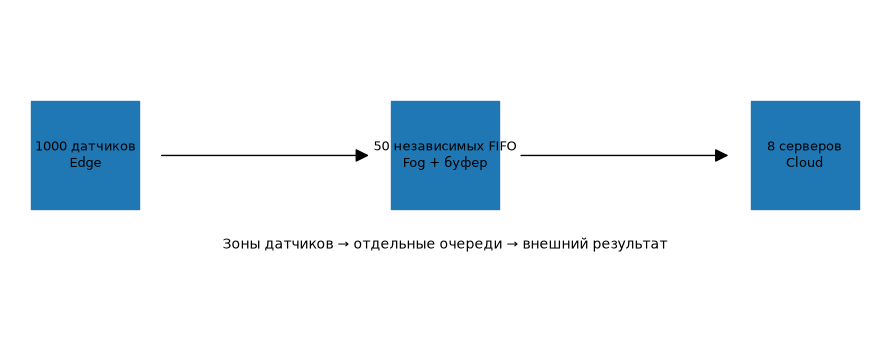

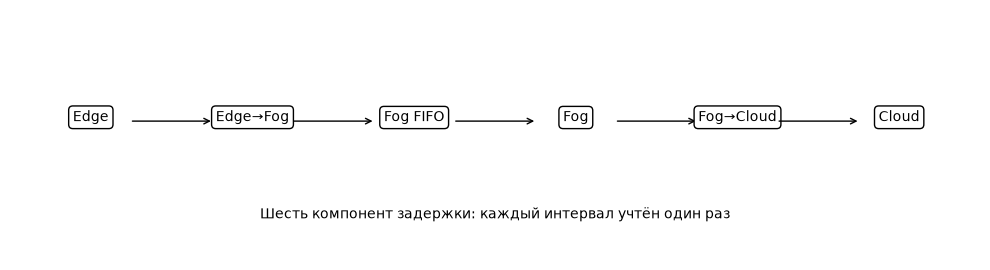

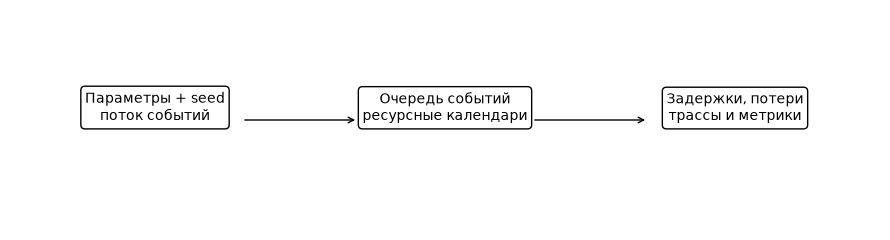

In [3]:
architecture()

Сравним конфигурации на одинаковых правилах. Стресс-серия 1200 событий/с отделена от парковочной нагрузки 400 событий/ч; по ней нельзя заявлять параметры реальной парковки.

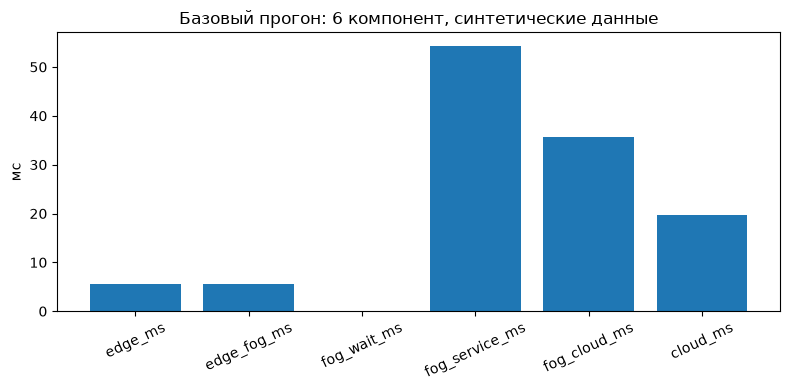

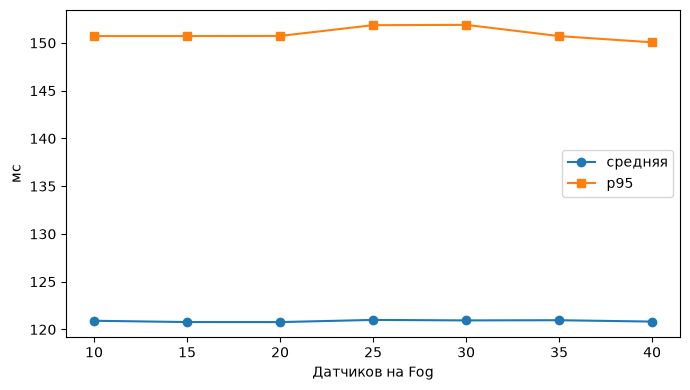

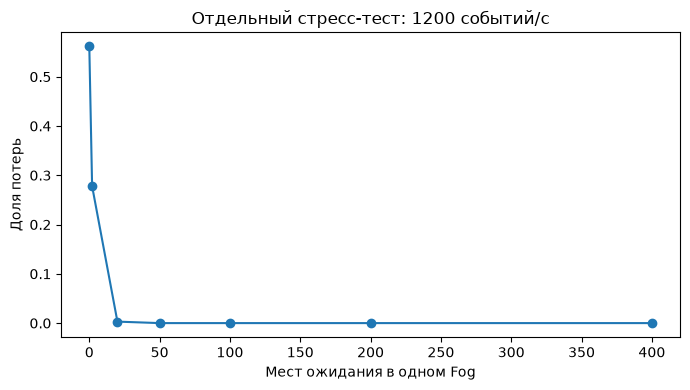

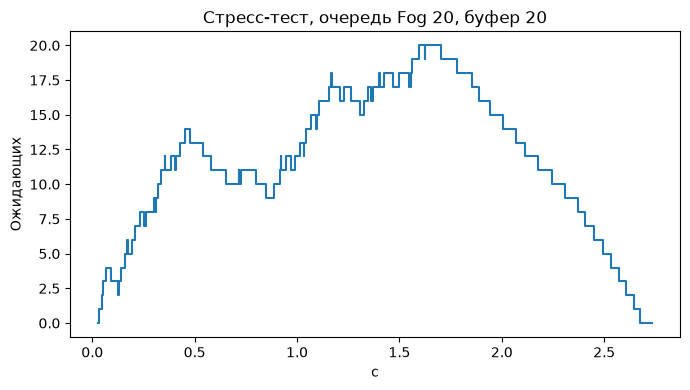

In [4]:
queue=pd.read_csv('results/stress_queue.csv')
configuration_plots(frame,queue)

Анимация одного события использует его рассчитанные интервалы, а не произвольную длительность. Базовая очередь может быть пустой — это также результат.

In [5]:
r=simulate()
html=animate_task(r['tasks'][0])
Path('results/event_animation.html').write_text(html)

300285

Стационарная диагностика: все50Fog, rho0,1–0,95, 10 независимых seed. Перед измерением прогрев2000 ожидаемых поступлений наFog, наблюдение4000 и хвост1000. Cloud40 только в этой серии обеспечивает устойчивую следующую стадию. Это не прежний переходный пик.

,series,scenario,rho_target,mean_ms,mean_ms_ci_low,mean_ms_ci_high,p95_ms,p95_ms_ci_low,p95_ms_ci_high,max_ms,max_ms_ci_low,max_ms_ci_high
0,intensity,rho_0.10,0.10000,124.553296,124.508356,124.598235,159.861123,159.748417,159.973828,326.514599,315.640144,337.389054
1,intensity,rho_0.30,0.30000,134.094850,134.019954,134.169746,195.171195,194.829690,195.512700,472.512835,448.415392,496.610279
2,intensity,rho_0.50,0.50000,151.185802,151.127687,151.243916,247.933284,247.491681,248.374888,686.184483,634.351791,738.017174
3,intensity,rho_0.70,0.70000,190.665813,190.342918,190.988708,367.122056,365.292549,368.951563,1048.787969,969.193660,1128.382278
4,intensity,rho_0.85,0.85000,288.530673,286.486666,290.574680,658.516192,649.483008,667.549375,1800.729005,1666.178965,1935.279044
5,intensity,rho_0.95,0.95000,689.359238,654.463886,724.254590,1861.031357,1742.593497,1979.469216,4650.867739,3848.077473,5453.658005
6,ratio,ratio_10,0.23750,130.595982,130.525940,130.666024,183.991962,183.694855,184.289069,434.397974,407.469360,461.326587
7,ratio,ratio_15,0.35625,137.851713,137.779070,137.924356,206.685047,206.361109,207.008986,523.758205,497.410748,550.105661
8,ratio,ratio_20,0.47500,148.348249,148.293079,148.403420,239.297807,238.879100,239.716515,655.411582,609.154890,701.668274
9,ratio,ratio_25,0.59375,164.932945,164.752441,165.113449,289.760990,288.757344,290.764636,830.261411,776.356947,884.165875


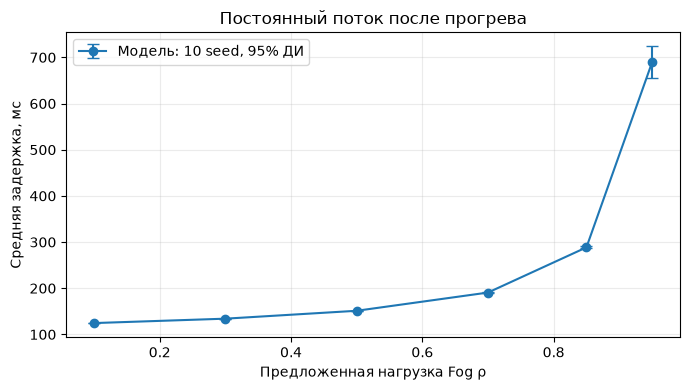

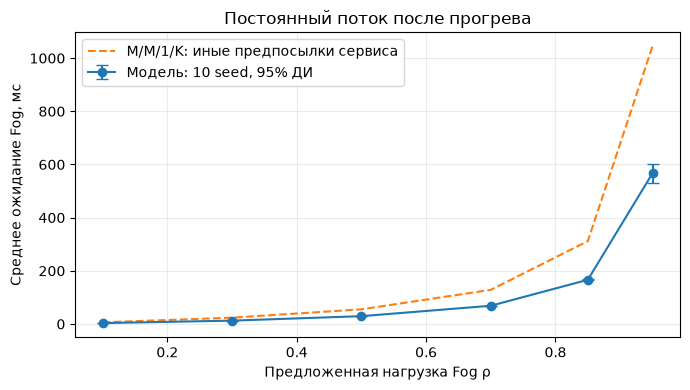

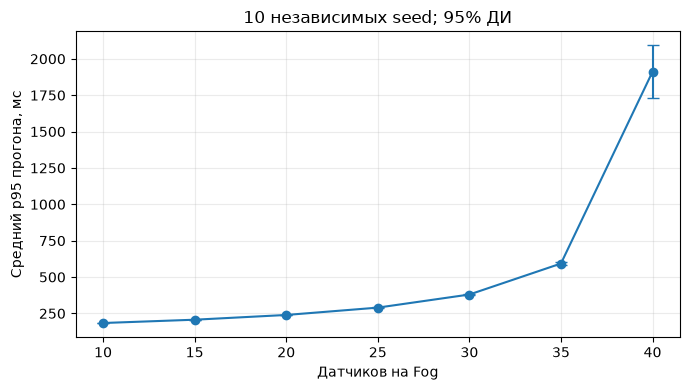

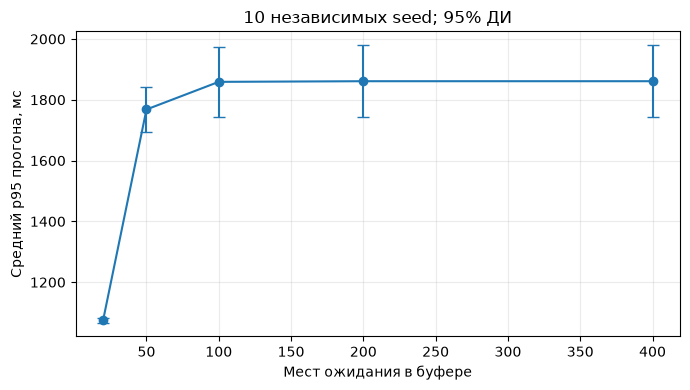

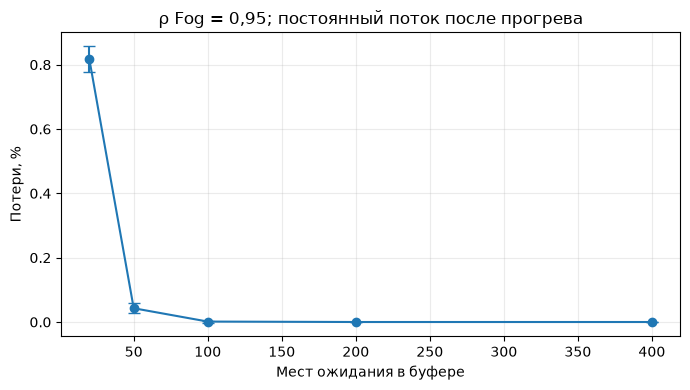

In [6]:
from efc.stationary import stationary_series
from efc.stationary_views import stationary_plots
steady,replicates=stationary_series()
display(steady[['series','scenario','rho_target','mean_ms','mean_ms_ci_low','mean_ms_ci_high','p95_ms','p95_ms_ci_low','p95_ms_ci_high','max_ms','max_ms_ci_low','max_ms_ci_high']])
stationary_plots(steady)
assert (steady.n_seeds>=10).all()
assert replicates.mean_fog_wait_ms.min()>0

Ползунки изменяют параметры нового запуска. Если ipywidgets отсутствует в локальной среде, сначала установите зависимости; статические результаты выше уже воспроизводимы.

In [7]:
try:
    import ipywidgets as w
    def explore(sensors=1000,fog=50,buffer=50,mobile=0.3):
        m=simulate(Config(n_edge=sensors,n_fog=fog,buffer=buffer,mobile_fraction=mobile))['metrics']
        print({k:m[k] for k in ('mean_ms','p95_ms','mean_fog_wait_ms','dropped')})
    display(w.interactive(explore,sensors=w.IntSlider(value=1000,min=500,max=2000,step=250),fog=w.IntSlider(value=50,min=25,max=100,step=25),buffer=w.IntSlider(value=50,min=0,max=400,step=10),mobile=w.FloatSlider(value=.3,min=0,max=1,step=.1)))
except ImportError:
    print('ipywidgets не установлен: интерактивные ползунки не проверены в этой среде.')

interactive(children=(IntSlider(value=1000, description='sensors', max=2000, min=500, step=250), IntSlider(val…

Проверка: баланс событий и сумма шести компонент. Таблица чисел предназначена для прямого переноса в статью с указанием источника.

In [8]:
assert (frame.completed+frame.dropped==frame.arrivals).all()
for row in r['tasks']:
    if row['status']=='completed':
        assert abs(sum(row[k] for k in COMPONENTS)-row['latency_ms'])<1e-6
b=frame.query("scenario=='baseline'").iloc[0]
display(pd.DataFrame({'число в статье':[b.mean_ms,b.p95_ms,b.mean_fog_wait_ms],'число модели':[r['metrics']['mean_ms'],r['metrics']['p95_ms'],r['metrics']['mean_fog_wait_ms']]},index=['средняя,мс','p95,мс','Fog-ожидание,мс']))
assert abs(b.mean_ms-r['metrics']['mean_ms'])<1e-9
print('OK')

,число в статье,число модели
"средняя,мс",120.767461,120.767461
"p95,мс",150.731387,150.731387
"Fog-ожидание,мс",0.000000,0.000000


OK


Чувствительность допущений: доля обработки Edge 0,3/0,5/0,7 и три диапазона Fog→Cloud. Все серии имеют rho Fog=0,70, тот же прогрев и10seed. Таблицы шести долей и трёх уровней явно включают каналы в родительский уровень.

,series,scenario,n_seeds,rho_target,n_edge,n_fog,n_cloud,buffer,arrival_rate_s,warmup_s,...,half_difference_p95_ms_ci_high,MM1K_wait_ms,edge_processing_share,fog_cloud_mean_ms,edge_ms,edge_fog_ms,fog_wait_ms,fog_service_ms,fog_cloud_ms,cloud_ms
0,edge_share,edge_share_0.3,10,0.7,1000,50,40,400,636.363636,157.142857,...,3.403060,128.333333,0.3,35.0,3.358915,8.303283,68.269162,54.99308,35.773932,20.003964
1,edge_share,edge_share_0.5,10,0.7,1000,50,40,400,636.363636,157.142857,...,3.388265,128.333333,0.5,35.0,5.602566,5.821082,68.471415,54.99308,35.773706,20.003964
2,edge_share,edge_share_0.7,10,0.7,1000,50,40,400,636.363636,157.142857,...,3.411479,128.333333,0.7,35.0,7.849723,3.433205,68.587921,54.99308,35.773419,20.003964
3,fog_cloud,fog_cloud_20.0,10,0.7,1000,50,40,400,636.363636,157.142857,...,3.370021,128.333333,0.5,20.0,5.602566,5.821082,68.471415,54.99308,20.003349,20.003964
4,fog_cloud,fog_cloud_35.0,10,0.7,1000,50,40,400,636.363636,157.142857,...,3.388265,128.333333,0.5,35.0,5.602566,5.821082,68.471415,54.99308,35.773706,20.003964
5,fog_cloud,fog_cloud_50.0,10,0.7,1000,50,40,400,636.363636,157.142857,...,3.760803,128.333333,0.5,50.0,5.602566,5.821082,68.471415,54.99308,59.241020,20.003964


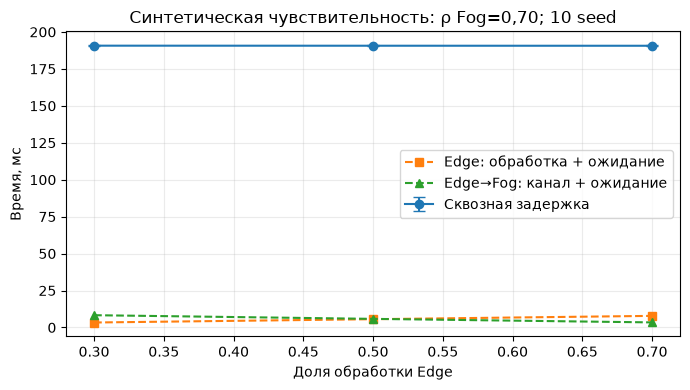

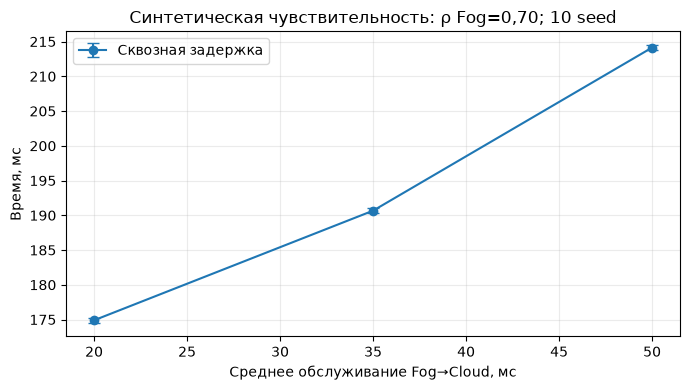

,component,mean_ms,share_pct
0,edge_ms,5.559104,4.603147
1,edge_fog_ms,5.559104,4.603147
2,fog_wait_ms,0.000000,0.000000
3,fog_service_ms,54.368739,45.019361
4,fog_cloud_ms,35.618254,29.493254
5,cloud_ms,19.662261,16.281091


,level,components,mean_ms,share_pct
0,Edge,edge_ms + edge_fog_ms,11.118207,9.206294
1,Fog,fog_wait_ms + fog_service_ms + fog_cloud_ms,89.986993,74.512615
2,Cloud,cloud_ms,19.662261,16.281091


In [9]:
from efc.sensitivity import sensitivity_series,sensitivity_plots
sensitive,sensitivity_raw=sensitivity_series()
display(sensitive)
sensitivity_plots(sensitive)
for name in ('component_shares','level_shares'):
    shares=pd.read_csv('results/'+name+'.csv')
    display(shares)
    assert abs(shares.share_pct.sum()-100)<1e-8

Проверка. Числа выполненной ячейки сравниваются с первичным файлом результатов и заносятся в общий results/claims.json. Несовпадение вызывает ошибку, а не косметическое сообщение OK.

In [10]:
from efc.claims import publish
base=frame[frame.scenario=='baseline'].iloc[0]
records=[{'id':'baseline_'+k,'value':float(base[k]),'file':'results/configuration.csv','where':{'scenario':'baseline'},'field':k} for k in ('mean_ms','p95_ms','mean_fog_wait_ms')]
records += [{'id':'stationary95_'+k,'value':float(steady[(steady.series=='intensity')&(steady.scenario=='rho_0.95')].iloc[0][k]),'file':'results/stationary_summary.csv','where':{'series':'intensity','scenario':'rho_0.95'},'field':k} for k in ('mean_ms','p95_ms','mean_fog_wait_ms','n_seeds')]
display(publish('01_Среда_и_конфигурация.ipynb',records))
print('OK: число в статье = число из модели')

,показатель,число в статье,число из модели,проверка
0,baseline_mean_ms,120.767461,120.767461,OK
1,baseline_p95_ms,150.731387,150.731387,OK
2,baseline_mean_fog_wait_ms,0.000000,0.000000,OK
3,stationary95_mean_ms,689.359238,689.359238,OK
4,stationary95_p95_ms,1861.031357,1861.031357,OK
5,stationary95_mean_fog_wait_ms,566.746996,566.746996,OK
6,stationary95_n_seeds,10.000000,10.000000,OK


OK: число в статье = число из модели
